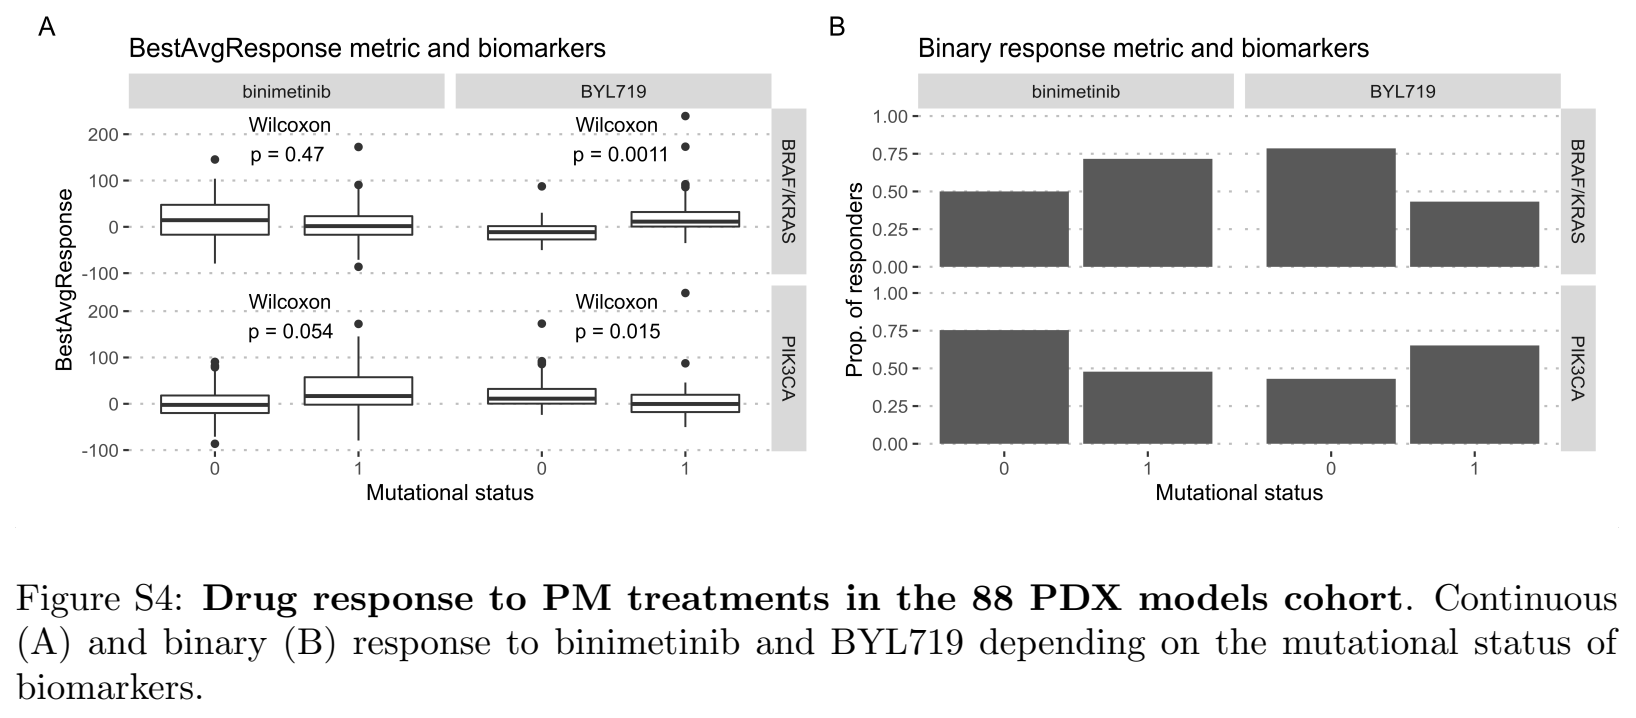

* 88 tumors are the patients/observations (rows)
* BRAF, KRAS, and PIK3CA are the 3 genes (features) we check for each tumor
* raw dataset starts with 281 different patient tumors (192 of which were genetically sequenced)

**TODO:** filter raw dataset to match paper aka extract the 88 tumors; ie. keeping only the tumors that meet all three rules:
1. they were genetically sequenced (they appear in pdxe_mut_and_cn2.csv)
2. they were tested on all 3 single drugs (binimetinib, BYL719, and LEE011)
3. they are eligible for the algorithm, meaning they have a mutation in at least one of those 3 genes (BRAF, KRAS, or PIK3CA)

*the algorithm:*
* binimetinib (MEK inhibitor) is recommended to KRAS/BRAF mutated tumours 
* BYL719 (alpha-specific PI3K inhibitor, also known as Alpelisib) recommended to PIK3CA mutated tumours

**TODO:** make one clean dataframe where EVERY row is an eligible tumor tested on binimetinib or BYL719, with columns for the outcome (BestAvgResponse, Responder) and 0/1 flags for whether that tumor has BRAF/KRAS or PIK3CA
* currently, that information is split across two different datasets pdxe_mut_and_cn2.csv & pct_curve_metrics.csv

### Exploring the Datasets

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

In [ ]:
mut = pd.read_csv("../data/pdxe_mut_and_cn2.csv")
metrics = pd.read_csv("../data/pct_curve_metrics.csv")

print("Mutation columns:", mut.columns.tolist())
print("Metrics columns:", metrics.columns.tolist())

print("Mutation categories:", mut["Category"].unique())
print("\n")

# Check different ways the 3 drugs were inputted
for d in ["binimetinib", "BYL719", "LEE011"]:
    matches = [x for x in metrics["Treatment"].dropna().unique() if d.lower() in x.lower()]
    print(d, "->", matches)

Mutation columns: ['Sample', 'Gene', 'Entrez', 'Category', 'Details']
Metrics columns: ['Model', 'Treatment', 'Treatment target', 'Treatment type', 'BestResponse', 'Day_BestResponse', 'BestAvgResponse', 'Day_BestAvgResponse', 'TimeToDouble', 'Day_Last', 'ResponseCategory']
Mutation categories: ['Amp5' 'MutNovel' 'Amp8' 'Del0.8' 'MutKnownFunctional'
 'MutLikelyFunctional']


binimetinib -> ['binimetinib', 'BYL719 + binimetinib', 'LFW527 + binimetinib', 'BKM120 + binimetinib', 'figitumumab" + binimetinib', 'INC424 + binimetinib', 'binimetinib-3.5mpk', 'LEE011 + binimetinib', 'encorafenib + binimetinib']
BYL719 -> ['BYL719', 'BYL719 + HSP990', 'BYL719 + LJM716', 'BYL719 + cetuximab', 'BYL719 + cetuximab + encorafenib', 'BYL719 + encorafenib', 'BYL719 + binimetinib', 'BYL719 + LEE011', 'BYL719 + LGH447']
LEE011 -> ['LEE011', 'LEE011 + everolimus', 'BYL719 + LEE011', 'LEE011 + encorafenib', 'LEE011 + binimetinib']


### Cleaning Data

In [16]:
drugs_3 = ["binimetinib", "BYL719", "LEE011"]
m3 = metrics[metrics["Treatment"].isin(drugs_3)].copy()

# find tumors that were tested on ALL 3 drugs
drug_counts = m3.groupby("Model")["Treatment"].nunique()
tested_all_3 = set(drug_counts[drug_counts == 3].index)

# tumor IDs that appear in the mutation file / to use for checking for genetically sequenced
sequenced_tumors = set(mut["Sample"].unique()) 

# lists of tumor IDs
# tumors w/ BRAF or KRAS mutation & one for tumors w/ PIK3CA mutation
braf_kras_ids = set(mut[mut["Gene"].isin(["BRAF", "KRAS"])]["Sample"])
pik3ca_ids = set(mut[mut["Gene"] == "PIK3CA"]["Sample"])

# apply the three eligibility filters
# keep only the tumors that are: tested on all 3 drugs AND sequenced AND mutated in (BRAF/KRAS OR PIK3CA)
eligible_ids = tested_all_3 & sequenced_tumors & (braf_kras_ids | pik3ca_ids)

# target values come from the plot
print("Total eligible tumors (target = 88):", len(eligible_ids))
print("BRAF/KRAS mutated (target = 74):", len(eligible_ids & braf_kras_ids))
print("PIK3CA mutated (target = 23):", len(eligible_ids & pik3ca_ids))

Total eligible tumors (target = 88): 88
BRAF/KRAS mutated (target = 74): 74
PIK3CA mutated (target = 23): 23


### Build Cleaned Dataframe for the Plots

In [17]:
# keep only the 88 eligible tumors AND only the 2 PM drugs shown in Figure S4
df = m3[(m3["Model"].isin(elig_all_cats)) & 
        (m3["Treatment"].isin(["binimetinib", "BYL719"]))].copy()

# add 0/1 columns for each biomarker
df["BRAF/KRAS"] = df["Model"].isin(braf_kras_ids).astype(int)
df["PIK3CA"] = df["Model"].isin(pik3ca_ids).astype(int)

# add 0/1 column for binary responder status (CR, PR, SD = 1; PD = 0)
df["Responder"] = df["ResponseCategory"].isin(["CR", "PR", "SD"]).astype(int)

# sanity check: 88 tumors * 2 drugs = 176 rows
print("Shape of plotting table:", df.shape)
df[["Model", "Treatment", "BestAvgResponse", "ResponseCategory", "BRAF/KRAS", "PIK3CA", "Responder"]].head()

Shape of plotting table: (176, 14)


,Model,Treatment,BestAvgResponse,ResponseCategory,BRAF/KRAS,PIK3CA,Responder
661,X-1004,BYL719,9.300,SD-->PD,1,0,0
675,X-1004,binimetinib,35.200,PD,1,0,0
728,X-1027,BYL719,15.025,PD,1,0,0
744,X-1027,binimetinib,35.800,PD,1,0,0
819,X-1156,BYL719,63.080,PD,1,0,0


### Replicate Plot A